analises

In [1]:
from __future__ import annotations

import argparse
import csv
from collections import defaultdict
from pathlib import Path
from statistics import mean, median, stdev
import numpy as np
import pandas as pd
from datetime import datetime
import math
import matplotlib.pyplot as plt
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if not (ROOT / 'src').exists():
    ROOT = (Path.cwd() / '..').resolve()
sys.path.insert(0, str(ROOT))

In [2]:

def carregar(caminho, columns, filter:dict = None):
    df = pd.read_csv(caminho, sep=',', header=0, usecols=columns)

    # sla se eu quiser aplicar algum filtro
    if filter:
        for key in filter:
            if key != "drop":
                df = df.loc[df[key] == filter[key]]
        if "drop" in filter: df = df.drop(columns=filter["drop"])

    #ordenação
    df = df.sort_values(by="ts_generation", ascending=True)
    # só pa ver :)
    df["date"] = pd.to_datetime(df["ts_generation"], unit="ms")
    # amostragem_ts(df)
    return df


def amostragem_ts(registro):
    # invervalos em segundos
    intervalos = [(registro["ts_generation"].iloc[i] - registro["ts_generation"].iloc[i-1])/1000 for i in range(1, registro.shape[0])]

    # entre a mediana
    intervalos_proximos_da_median = [
        intervalo for intervalo in intervalos if math.ceil(median(intervalos)-30) <= intervalo <= math.ceil(median(intervalos)+30)
    ]

    print(f"Intervalo mediano: {median(intervalos):.2f} s")
    print(f"Intervalo médio: ",f"{mean(intervalos):.2f} s ± {stdev(intervalos):.2f} s")
    print(f"Intervalos entre ± 30 s da mediana: {len(intervalos_proximos_da_median) / len(intervalos):.2%}", end="\n\n")

def tempo_proximo_evento(df):
    # ordenar por datatime...
    df = df.sort_values(by="ts_generation", ascending=True)
    
    # EVENTOS DE TRANSIÇÃO: 
    estado_anterior = df["valve_state"].shift(1)

    # 0 -> 1
    transicao = (
        estado_anterior.eq(0)
        & df["valve_state"].eq(1)
    )

    eventos = (df.loc[transicao].copy()).sort_values(by="ts_generation", ascending=True)

    eventos = eventos.drop(columns=["valve_state"])

    # TEMPO DE UM EVENTO DE IRRIGAÇÃO PARA OUTRO:
    ts = eventos["ts_generation"].to_numpy()

    # ts de i - (i-1) em s
    tempo_para_proxima = np.ceil((ts[1:] - ts[:-1]) / (60*1000))

    # tempo proxima irrigacao
    eventos["t_pi"] = np.r_[tempo_para_proxima, np.nan] if len(ts) else np.array([], dtype=float)

    return eventos


In [3]:
ANO = "2024"
LINHA = 3
DISPOSITIVO_SOIL = "2f2ba968948ac82e9517eddb42fc1043d211d6da9f0725cd47ce2fb995701b92"

ENTRADA_VALVE = ROOT / "data" / "raw" / ANO / f"valve_controller{ANO}.csv"
ENTRADA_ENVIRONMENTAL = ROOT / "data" / "raw" / ANO / f"environmental{ANO}.csv"
ENTRADA_INDICADOR = ROOT / "data" / "raw" / ANO / f"indicators{ANO}.csv"
ENTRADA_SOIL = ROOT / "data" / "raw" / ANO / f"soil{ANO}.csv"
ENTRADA_MEDIDOR = ROOT  / "data" / "raw" / ANO / f"water_meter{ANO}.csv"

COLUMNS_VALVE = {"ts_generation", "line", "valve_state"}
COLUMNS_ENV = {"ts_generation", "temperature", "humidity"}
COLUMNS_GDD = {"ts_generation", "gdd"}
COLUMNS_SOIL = {"ts_generation", "line", "humidity", "generated_by"}
COLUMNS_MEDIDOR = {"ts_generation", "line", "current_volume"}

FILTER_VALVE = {"line": LINHA, "drop": ["line"]}
FILTER_SOIL = {"line": LINHA, "generated_by": DISPOSITIVO_SOIL,  "drop": ["line", "generated_by"]} # filtrando por dispositivo 15cm
FILTER_MEDIDOR = {"line": LINHA, "drop": ["line"]}

In [4]:
registros_valve = carregar(ENTRADA_VALVE, filter=FILTER_VALVE, columns=COLUMNS_VALVE)
print(registros_valve.shape)
registros_env = carregar(ENTRADA_ENVIRONMENTAL, columns=COLUMNS_ENV)
registros_env = registros_env.rename(columns={"temperature":"temperature_env","humidity": "humidity_env"})
print(registros_env.shape)
registros_gdd = carregar(ENTRADA_INDICADOR, columns=COLUMNS_GDD)
print(registros_gdd.shape)
registros_soil = carregar(ENTRADA_SOIL, filter=FILTER_SOIL, columns=COLUMNS_SOIL)
registros_soil = registros_soil.rename(columns={"humidity": "humidity_soil"})
print(registros_soil.shape)
registros_medidor = carregar(ENTRADA_MEDIDOR, filter=FILTER_MEDIDOR, columns=COLUMNS_MEDIDOR)
registros_medidor["volume_incremento"] = registros_medidor["current_volume"].diff()
registros_medidor["volume_incremento"] = registros_medidor["volume_incremento"].where(
    registros_medidor["volume_incremento"].ge(0)
)
print(registros_medidor.shape)

(11658, 3)
(9327, 4)
(205, 3)
(13334, 3)
(13186, 4)


In [5]:
registros_medidor.columns

Index(['ts_generation', 'current_volume', 'date', 'volume_incremento'], dtype='object')

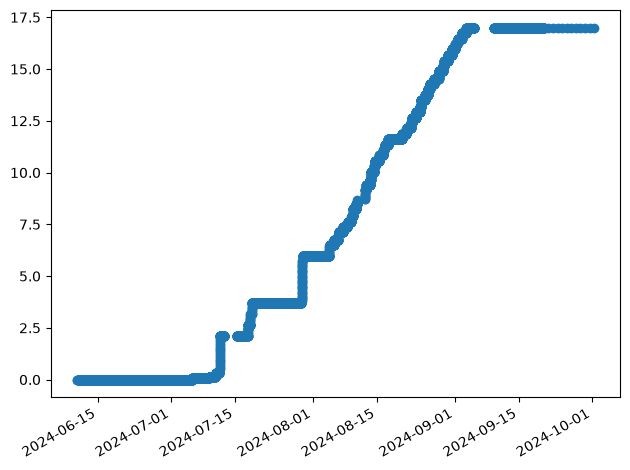

In [6]:
plt.scatter(registros_medidor["date"],registros_medidor["current_volume"]*0.001)
plt.gcf().autofmt_xdate()
plt.tight_layout()
plt.show()

PROBLEMA: 
1. o sensoriamento tem intervalos médios e medianos próximos, mas estão desalinhados
2. União com merge retornar nenhum elemento, por causa das diferenças em ts

uniao com merge asof (vizinhos + exatos)

In [7]:
registros_valve

,ts_generation,valve_state,date
821,1718150448883,0.0,2024-06-12 00:00:48.883
830,1718151648866,0.0,2024-06-12 00:20:48.866
839,1718152848858,0.0,2024-06-12 00:40:48.858
848,1718154048848,0.0,2024-06-12 01:00:48.848
857,1718155248822,0.0,2024-06-12 01:20:48.822
...,...,...,...
58585,1725508977466,0.0,2024-09-05 04:02:57.466
58590,1725509577461,0.0,2024-09-05 04:12:57.461
58595,1725510177451,0.0,2024-09-05 04:22:57.451
58600,1725510777445,0.0,2024-09-05 04:32:57.445


In [8]:
def identificar_amostragem(
    df,
    intervalo=600,
    epsilon=40, # s
    confirmacoes=3
):
    dados = df.sort_values("ts_generation").copy()

    ts = dados["ts_generation"].to_numpy(dtype=np.int64)
    n = len(ts)

    status = np.full(n, "suspeita", dtype=object)
    grupo = np.full(n, -1, dtype=int)

    if n == 0:
        dados["status_amostragem"] = status
        dados["grupo_amostragem"] = grupo
        dados["amostra_valida"] = np.array([], dtype=bool)
        return dados

    # Tudo em milissegundos
    intervalo *= 1000
    epsilon *= 1000

    def intervalo_valido(a, b, ciclos=1):
        dt = ts[b] - ts[a]
        return abs(dt - ciclos * intervalo) <= epsilon

    def proximo_valido(pos, ciclos=1):
        candidatos = [
            j for j in range(pos + 1, n)
            if intervalo_valido(pos, j, ciclos)
        ]

        if not candidatos:
            return None

        return min(
            candidatos,
            key=lambda j: abs(
                (ts[j] - ts[pos]) - ciclos * intervalo
            )
        )

    def confirmar_sequencia(inicio):
        atual = inicio

        for _ in range(confirmacoes - 1):
            prox = proximo_valido(atual)

            if prox is None:
                return False

            atual = prox

        return True

    ultimo_correto = 0
    grupo_atual = 0

    status[0] = "regular"
    grupo[0] = grupo_atual

    while ultimo_correto < n - 1:

        # 1. Procura o próximo registro em ~10 minutos
        prox = proximo_valido(ultimo_correto)

        if prox is not None:
            status[prox] = "regular"
            grupo[prox] = grupo_atual
            ultimo_correto = prox
            continue

        # 2. Procura uma nova sequência consistente
        nova = None

        for j in range(ultimo_correto + 1, n):
            if confirmar_sequencia(j):
                nova = j
                break

        # 3. Confirma mudança da referência temporal
        if nova is not None:
            grupo_atual += 1

            status[nova] = "nova_sequencia"
            grupo[nova] = grupo_atual

            ultimo_correto = nova
            continue

        # 4. Não encontrou nova sequência.
        # Verifica possível perda de 1 ou 2 amostras.
        recuperado = None

        for ciclos in (2, 3):
            recuperado = proximo_valido(
                ultimo_correto, ciclos=ciclos
            )
            if recuperado is not None:
                break

        if recuperado is not None:
            status[recuperado] = "regular"
            grupo[recuperado] = grupo_atual
            ultimo_correto = recuperado
            continue

        # Não há evidência suficiente para classificar
        break

    dados["status_amostragem"] = status
    dados["grupo_amostragem"] = grupo
    dados["amostra_valida"] = dados["status_amostragem"].ne("suspeita")

    return dados

In [9]:
# df_validado = identificar_amostragem(
#     registros_valve,
#     intervalo=600,
#     epsilon=40,
#     confirmacoes=3
# )

# print(df_validado["status_amostragem"].value_counts())

In [10]:
# registros_medidor[registros_medidor["current_volume"]>0]

In [11]:
# registros_valve[registros_valve["valve_state"]==1.0]

* tem que juntar o estado da valvula estando 2 minutos antes comparado ao medidor 
* tem amostras esquisitas pelo intervalo: 2024-07-10 15:17:56.827000 (21377) o proximo seria 2024-07-10 15:27:42.619000 (21384), mas tem algo em 2024-07-10 15:21:51.257000 (21382), sendo que **Sampling rate:** every 10 minutes

In [12]:
dft = pd.merge_asof(registros_valve,registros_medidor, on="ts_generation", direction="forward", tolerance=2*60*1000)
dft = dft.drop(columns=["date_y"])
print(dft["ts_generation"].is_monotonic_increasing)
print(tempo_proximo_evento(dft).shape)
# print(dft.columns)

# inconsistencia entre valvula e medidor da vazão:
inconsistencias = dft.loc[
    (dft["valve_state"] == 0) &
    (dft["volume_incremento"] > 0)
]

print(f"Registros sem pareamento com o medidor: {dft['current_volume'].isna().sum()}")
print(f"Inconsistências encontradas: {len(inconsistencias)}")
display(inconsistencias)

True
(74, 5)
Registros sem pareamento com o medidor: 9770
Inconsistências encontradas: 12


,ts_generation,valve_state,date_x,current_volume,volume_incremento
3375,1720191466607,0.0,2024-07-05 14:57:46.607,22.0,22.0
3376,1720192066662,0.0,2024-07-05 15:07:46.662,63.0,41.0
3377,1720192666670,0.0,2024-07-05 15:17:46.670,93.0,30.0
3904,1720510063557,0.0,2024-07-09 07:27:43.557,102.0,9.0
3906,1720510131125,0.0,2024-07-09 07:28:51.125,102.0,9.0
3907,1720510663542,0.0,2024-07-09 07:37:43.542,110.0,8.0
3909,1720510731103,0.0,2024-07-09 07:38:51.103,110.0,8.0
4103,1720624730167,0.0,2024-07-10 15:18:50.167,136.0,12.0
4106,1720625276867,0.0,2024-07-10 15:27:56.867,194.0,58.0
4742,1721237332145,0.0,2024-07-17 17:28:52.145,2460.0,69.0


In [13]:
dft = pd.merge_asof(registros_valve,registros_medidor, on="ts_generation", direction="forward", tolerance=2*60*1000)
dft = dft.drop(columns=["date_y"])
print(dft["ts_generation"].is_monotonic_increasing)
print(tempo_proximo_evento(dft).shape)
# print(dft.columns)

# inconsistencia entre valvula e medidor da vazão:
inconsistencias = dft.loc[
    (dft["valve_state"] == 0) &
    (dft["volume_incremento"] > 0)
]

print(f"Registros sem pareamento com o medidor: {dft['current_volume'].isna().sum()}")
print(f"Inconsistências encontradas: {len(inconsistencias)}")
display(inconsistencias)

True
(74, 5)
Registros sem pareamento com o medidor: 9770
Inconsistências encontradas: 12


,ts_generation,valve_state,date_x,current_volume,volume_incremento
3375,1720191466607,0.0,2024-07-05 14:57:46.607,22.0,22.0
3376,1720192066662,0.0,2024-07-05 15:07:46.662,63.0,41.0
3377,1720192666670,0.0,2024-07-05 15:17:46.670,93.0,30.0
3904,1720510063557,0.0,2024-07-09 07:27:43.557,102.0,9.0
3906,1720510131125,0.0,2024-07-09 07:28:51.125,102.0,9.0
3907,1720510663542,0.0,2024-07-09 07:37:43.542,110.0,8.0
3909,1720510731103,0.0,2024-07-09 07:38:51.103,110.0,8.0
4103,1720624730167,0.0,2024-07-10 15:18:50.167,136.0,12.0
4106,1720625276867,0.0,2024-07-10 15:27:56.867,194.0,58.0
4742,1721237332145,0.0,2024-07-17 17:28:52.145,2460.0,69.0


In [14]:
df_temp = pd.merge_asof(dft,registros_soil, on="ts_generation", direction="nearest", tolerance=10*60*1000)
df_temp = df_temp.drop(columns=["date"])
print(df_temp["ts_generation"].is_monotonic_increasing)
print(tempo_proximo_evento(df_temp).shape)
# print(registros_valve.columns,registros_soil.columns)
# print(df_temp.columns)

df_temp_1 = pd.merge_asof(df_temp, registros_env, on="ts_generation", direction="nearest", tolerance=10*60*1000)
df_temp_1 = df_temp_1.drop(columns=["date"])
print(df_temp_1["ts_generation"].is_monotonic_increasing)
print(tempo_proximo_evento(df_temp_1).shape)
# print(registros_env.columns)
print(df_temp_1.columns)

df_temp_1 = df_temp_1.dropna(subset=["valve_state", "humidity_soil", "temperature_env", "humidity_env"])
df_temp_1 = df_temp_1.drop(columns=[ "date_x"])
df_temp_1.shape
# df_temp_1.columns

True
(74, 6)
True
(74, 8)
Index(['ts_generation', 'valve_state', 'date_x', 'current_volume',
       'volume_incremento', 'humidity_soil', 'temperature_env',
       'humidity_env'],
      dtype='object')


(9480, 7)

In [15]:
df_aut = df_temp_1.copy()

#ordenação
df_aut = df_aut.sort_values(by="ts_generation", ascending=True)
# só pa ver :)
df_aut["date"] = pd.to_datetime(df_aut["ts_generation"], unit="ms")

# aplicando lags de 10 minutos e 20 minutos (1 e 2 amostras passadas)
for lag in (1, 2, 3):
    coluna_ts = f"ts_lag_{lag}"
    historico = df_temp[["ts_generation", "humidity_soil", "valve_state"]].rename(columns={
        "ts_generation": coluna_ts,
        "humidity_soil": f"humidity_soil_lag_{lag}",
        "valve_state": f"valve_state_lag_{lag}",
    })
    df_aut["ts_busca"] = df_aut["ts_generation"] - lag * 10 * 60_000
    df_aut = pd.merge_asof(
        df_aut, historico, left_on="ts_busca", right_on=coluna_ts,
        direction="nearest", tolerance=60_000,
    ).drop(columns="ts_busca")

estado_anterior = registros_valve["valve_state"].shift(1)
fim_irrigacao = registros_valve["valve_state"].eq(0) & estado_anterior.eq(1)
historico_fins = registros_valve.loc[fim_irrigacao, ["ts_generation"]].rename(columns={"ts_generation": "ts_fim"})
df_aut = pd.merge_asof(
    df_aut, historico_fins, left_on="ts_generation", right_on="ts_fim", direction="backward",
)
df_aut["fim_irrigacao"] = df_aut["ts_generation"].eq(df_aut["ts_fim"])
df_aut = df_aut.dropna(subset=["humidity_soil_lag_1", "humidity_soil_lag_2"])
df_aut

,ts_generation,valve_state,current_volume,volume_incremento,humidity_soil,temperature_env,humidity_env,date,ts_lag_1,humidity_soil_lag_1,valve_state_lag_1,ts_lag_2,humidity_soil_lag_2,valve_state_lag_2,ts_lag_3,humidity_soil_lag_3,valve_state_lag_3,ts_fim,fim_irrigacao
23,1718176685991,0.0,NaN,NaN,0.00,21.4,85.0,2024-06-12 07:18:05.991,1.718176e+12,0.00,0.0,1.718175e+12,0.00,0.0,NaN,NaN,NaN,NaN,False
24,1718177285991,0.0,NaN,NaN,0.00,21.5,82.0,2024-06-12 07:28:05.991,1.718177e+12,0.00,0.0,1.718176e+12,0.00,0.0,1.718175e+12,0.00,0.0,NaN,False
25,1718177885980,0.0,NaN,NaN,0.00,21.5,82.0,2024-06-12 07:38:05.980,1.718177e+12,0.00,0.0,1.718177e+12,0.00,0.0,1.718176e+12,0.00,0.0,NaN,False
26,1718178485973,0.0,NaN,NaN,0.00,22.3,81.0,2024-06-12 07:48:05.973,1.718178e+12,0.00,0.0,1.718177e+12,0.00,0.0,1.718177e+12,0.00,0.0,NaN,False
27,1718179085964,0.0,NaN,NaN,0.00,22.8,80.0,2024-06-12 07:58:05.964,1.718178e+12,0.00,0.0,1.718178e+12,0.00,0.0,1.718177e+12,0.00,0.0,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9475,1725501777538,0.0,NaN,NaN,26.42,19.7,100.0,2024-09-05 02:02:57.538,1.725501e+12,26.42,0.0,1.725501e+12,26.42,0.0,1.725500e+12,26.42,0.0,1.725365e+12,False
9476,1725502377535,0.0,NaN,NaN,26.42,19.7,100.0,2024-09-05 02:12:57.535,1.725502e+12,26.42,0.0,1.725501e+12,26.42,0.0,1.725501e+12,26.42,0.0,1.725365e+12,False
9477,1725502977531,0.0,NaN,NaN,26.42,19.9,100.0,2024-09-05 02:22:57.531,1.725502e+12,26.42,0.0,1.725502e+12,26.42,0.0,1.725501e+12,26.42,0.0,1.725365e+12,False
9478,1725503577537,0.0,NaN,NaN,26.42,20.0,100.0,2024-09-05 02:32:57.537,1.725503e+12,26.42,0.0,1.725502e+12,26.42,0.0,1.725502e+12,26.42,0.0,1.725365e+12,False


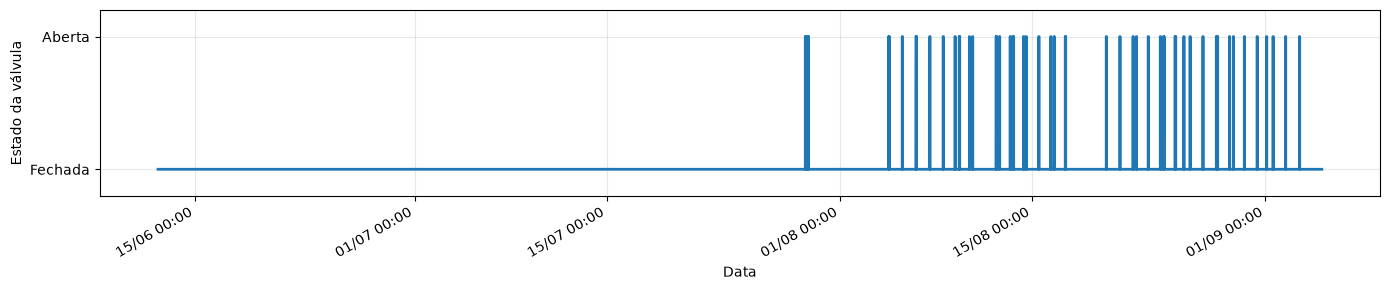

In [16]:
# distribuição com valvula aberta e sem
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(14, 3))

ax.step(
    df_aut["date"],
    df_aut["valve_state"],
    where="post",
    linewidth=2
)

ax.set_yticks([0, 1])
ax.set_yticklabels(["Fechada", "Aberta"])
ax.set_ylim(-0.2, 1.2)
ax.set_xlabel("Data")
ax.set_ylabel("Estado da válvula")
ax.grid(alpha=0.3)

ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %H:%M"))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**obs1**: foi observado que uma data da df_2 pode ser pareada com mais do que uma df_1, dado que ele faz um how left


> **talvez futuro**: algo minimize a diferença de tempo entre os pares, em que 
> 1. Cada registro da df_1 pode ser associado a apenas um registro da df_2.
> 2. Cada registro da df_2 só pode ser utilizado uma vez.
> 3. com uma tolerancia em minutos. 

  ## NAO APLICADO  autoregressivo

Regras de composição do data (preguiça t_T):
1. i, se v_i = 0 e v_j = 0 para todo j pertence (i-10,i-20,i-30)
2. i, se v_i = 1 e umidade_j != Null para todo j pertence (i-10,i-20,i-30)
composição deve ter:
* umid_solo; umid_ar; temp_ar; ts; valve_state; umid_solo(t-10); umid_solo(t-20); umid_solo(t-30); t_i (tempo de irrigação)

## Analises

entradas: erro = 27% [fonte:baseline] - h(t); dh_20min = (h(t) - h(t-2))/20

saídas: tempo de irrigação

ideia:
* erro: excesso, transicao, deficit
* dh_20min: diminuindo, estavel, aumentando
* ti: desligado, curto, longo

### bomba

count     74.000000
mean      28.777076
std       22.006776
min        0.885300
25%       29.859646
50%       29.885750
75%       29.922492
max      200.005883
Name: Duração (min), dtype: float64


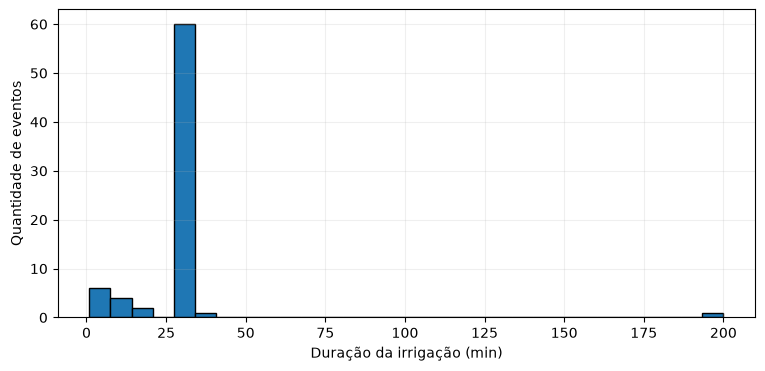

In [17]:
base = registros_valve.sort_values("ts_generation").copy()

# Identificar início e fim das irrigações
base["inicio"] = (
    base["valve_state"].eq(1)
    & base["valve_state"].shift(1).eq(0)
)

base["fim"] = (
    base["valve_state"].eq(0)
    & base["valve_state"].shift(1).eq(1)
)

# Timestamps dos eventos
inicios = base.loc[base["inicio"], "ts_generation"].to_numpy()
fins = base.loc[base["fim"], "ts_generation"].to_numpy()

# relaciona cada início ao próximo desligamento
pos = np.searchsorted(fins, inicios, side="right")
validos = pos < len(fins)

duracoes = (
    fins[pos[validos]] - inicios[validos]
) / 60_000

duracoes = pd.Series(duracoes, name="Duração (min)")

# display(
#     duracoes.describe(
#         percentiles=[.05, .25, .50, .75, .95]
#     ).to_frame().style.format("{:.2f}")
# )

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(duracoes, bins=30, edgecolor="black")
print(duracoes.describe())

ax.set_xlabel("Duração da irrigação (min)")
ax.set_ylabel("Quantidade de eventos")
ax.grid(alpha=0.2)

plt.show()

### analise de antes e apos evento de irrigação

In [18]:
base = df_aut.sort_values("ts_generation").copy()

base["dh_20min"] = (
    base["humidity_soil"]
    - base["humidity_soil_lag_2"]
) / 20  # 20 garantido por causa do filtro

# Identifica quando a válvula passa de ligada (1) para desligada (0)
base["fim_irrigacao"] = base["ts_generation"].eq(base["ts_fim"])

# Tempo desde o último desligamento
base["min_apos_fim"] = (
    base["ts_generation"] - base["ts_fim"]
) / 60_000

# Mantém somente intervalos válidos para dh_20min
base["intervalo_min"] = (
    base["ts_generation"] - base["ts_lag_2"]
) / 60_000

validos = (base["intervalo_min"].between(19, 21)
           & ((base["ts_generation"] - base["ts_lag_1"]) / 60_000).between(9, 11))

# Secagem: válvula desligada há mais de 60 minutos
secagem = (
    validos
    & base["valve_state"].eq(0)
    & base["valve_state_lag_1"].eq(0)
    & base["valve_state_lag_2"].eq(0)
    & (
        base["min_apos_fim"].gt(60)
        | base["min_apos_fim"].isna()
    )
)

# Pós-irrigação: janela de 20 a 60 minutos após o desligamento
pos_irrigacao = (
    validos
    & base["valve_state"].eq(0)
    & base["min_apos_fim"].between(20, 60)
)

comparacao = pd.DataFrame({
    "Secagem": base.loc[secagem, "dh_20min"].describe(
        percentiles=[.05, .25, .50, .75, .95]
    ),
    "Pós-irrigação": base.loc[pos_irrigacao, "dh_20min"].describe(
        percentiles=[.05, .25, .50, .75, .95]
    )
})

display(comparacao.style.format("{:.5f}"))

,Secagem,Pós-irrigação
count,8785.00000,154.00000
mean,-0.00218,-0.04035
std,0.01848,0.01894
min,-0.18050,-0.09400
5%,-0.01600,-0.06650
25%,-0.00350,-0.05187
50%,0.00000,-0.04250
75%,0.00000,-0.03200
95%,0.00300,-0.00995
max,0.87200,0.05150


bem distindos o dh_20min comparando um periodo de seca com um apos um evento de irrigação

In [19]:
# tempo ate proxima amostra -
eventos = registros_valve.loc[fim_irrigacao].copy()

eventos["min_proxima_amostra"] = (
    registros_valve["ts_generation"].shift(-1).loc[eventos.index]
    - eventos["ts_generation"]
) / 60_000

display(
    eventos["min_proxima_amostra"]
    .describe(percentiles=[.05, .25, .50, .75, .95])
    .to_frame("Minutos até próxima amostra")
    .style.format("{:.2f}")
)

,Minutos até próxima amostra
count,74.00
mean,41.97
std,280.21
min,0.24
5%,5.53
25%,9.75
50%,9.85
75%,9.87
95%,9.89
max,2419.85


### analises da umidade e dos intervalos -> para possivel filtro


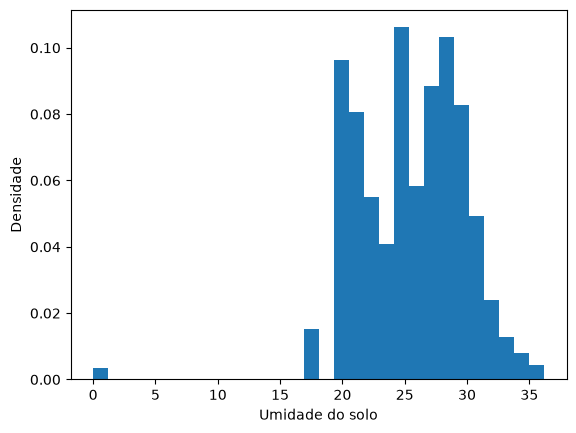

Avaliando a umidade do solo: 
 count    9322.000000
mean       25.457653
std         4.313207
min         0.000000
5%         19.620000
10%        20.110000
25%        21.930000
50%        25.510000
75%        28.600000
90%        30.410000
95%        31.680000
max        36.180000
Name: humidity_soil, dtype: float64
Amplitude: 36.18


In [20]:
import matplotlib.pyplot as plt

h = df_aut["humidity_soil"]


fig, ax = plt.subplots()
ax.hist(h, bins=30, density=True)
ax.set_xlabel("Umidade do solo")
ax.set_ylabel("Densidade")
plt.show()

print("Avaliando a umidade do solo: \n", h.describe(
    percentiles=[.05, .10, .25, .50, .75, .90, .95]
))
print("Amplitude:", h.max() - h.min())

In [21]:
# Analisando amostragem para verifciar se há concentração em 20 minutos

df_check = df_aut.sort_values("ts_generation").copy()

df_check["intervalo_min"] = (
    df_check["ts_generation"]
    - df_check["ts_lag_2"]
) / 60_000

display(
    df_check["intervalo_min"].describe(
        percentiles=[.05, .25, .50, .75, .95]
    )
)

# vendo intervalos fora de 20 minutos
intervalo = df_check["intervalo_min"]

print("Intervalos fora de 19–21 min:",
      (~intervalo.between(19, 21) & intervalo.notna()).sum())

print("Percentual:",
      (~intervalo.between(19, 21) & intervalo.notna()).mean() * 100)

count    9322.000000
mean       20.002245
std         0.038391
min        19.732317
5%         19.999500
25%        19.999717
50%        19.999800
75%        19.999900
95%        20.000383
max        20.381033
Name: intervalo_min, dtype: float64

Intervalos fora de 19–21 min: 0
Percentual: 0.0


pela mediana e p5 a p95 -> boa regularidade;

min e max -> tem lacunas;

lacunas -> só 4%, então ok

In [22]:
# filtro em 95%
# Intervalos regulares

mask = df_check["intervalo_min"].between(19, 21)

# Dados específicos para análise temporal
df_dinamica = df_check.loc[mask].copy()

# Verificar os registros restantes
print("Observações:", len(df_dinamica))
print("Percentual mantido:", f"{mask.mean():.2%}")

Observações: 9322
Percentual mantido: 100.00%


### definição de universos e funções de pertinencia

In [23]:
# Referência do baseline
setpoint = 27

# Erro de controle
df_dinamica["erro"] = setpoint - df_dinamica["humidity_soil"]
e = df_dinamica["erro"]

# Variação média da umidade por minuto
df_dinamica["dh_20min"] = (
    df_dinamica["humidity_soil"]
    - df_dinamica["humidity_soil_lag_2"]
) / 20  # 20 garantido por causa do filtro
d = df_dinamica["dh_20min"]

# o erro não precisaria do filtro, porque observa o inst atual, mas para facilitar a metodologia, vou manter em ambos, já que o dh20 precisa

#### analise do erro

* ver a distribuição do erro e em relação aos limiares de 24% e 27% do baseline

,Erro
count,9322.0000
mean,1.5423
std,4.3132
min,-9.1800
5%,-4.6800
10%,-3.4100
25%,-1.6000
50%,1.4900
75%,5.0700
90%,6.8900


Erro = 0: quando h(t) é 27%, enquanto erro = 3: quando h(t) é 24%
Os dois limiares do baseline


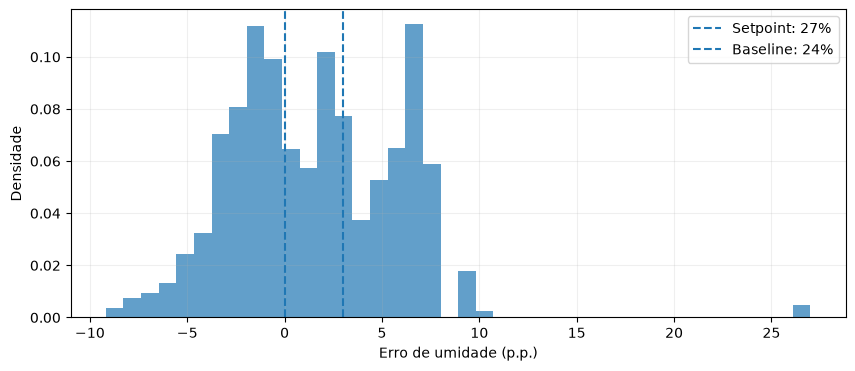

In [24]:
# descritivas do erro
percentis = [.05, .10, .25, .50, .75, .90, .95]

display(
    e.describe(percentiles=percentis)
    .to_frame("Erro")
    .style.format("{:.4f}")
)

# distribuição do erro
print("Erro = 0: quando h(t) é 27%, enquanto erro = 3: quando h(t) é 24%", "Os dois limiares do baseline", sep='\n')
fig, ax = plt.subplots(figsize=(10, 4))

ax.hist(e, bins=40, density=True, alpha=0.7)

ax.axvline(0, linestyle="--", label="Setpoint: 27%")
ax.axvline(3, linestyle="--", label="Baseline: 24%")

ax.set_xlabel("Erro de umidade (p.p.)")
ax.set_ylabel("Densidade")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

* universo aproximado [−20, 27]
* parece duas modass

In [25]:
# ver o quanto do histórico ficou em cada faixa operacional do baseline 
regioes = pd.DataFrame({
    "Região": [
        "Acima de 27%",
        "Entre 24% e 27%",
        "Abaixo de 24%"
    ],
    "Quantidade": [
        (e < 0).sum(),
        ((e >= 0) & (e <= 3)).sum(),
        (e > 3).sum()
    ]
})

regioes["Percentual"] = regioes["Quantidade"] / len(e)

display(
    regioes.style.format({
        "Quantidade": "{:,.0f}",
        "Percentual": "{:.1%}"
    }).hide(axis="index")
)

Região,Quantidade,Percentual
Acima de 27%,"3,980",42.7%
Entre 24% e 27%,"2,250",24.1%
Abaixo de 24%,"3,092",33.2%


* erro +10 ou +20, é déficit significativamente igual -> pertinencia de um deficit não reduz, pq tá longe da moda -> trapézio

em relação a ref:
* e < 0: acima de 27% -> excesso de umidade
* 0 <= e <= 3: entre 24 e 27% -> mantem o ultimo estado da valvula  
* e > 3: a baixo de 24% -> deficit q aciona irrigação no baseline

trapezoide em todos

#### analise do df_20min

* ver a escala das variações e como seria umidade diminuindo, estável ou aumentando aqui


Descrição de dh_20min:


,dh_20min
count,9322.00000
mean,0.00169
std,0.04346
min,-0.18050
5%,-0.01900
10%,-0.01150
25%,-0.00350
50%,0.00000
75%,0.00000
90%,0.00200


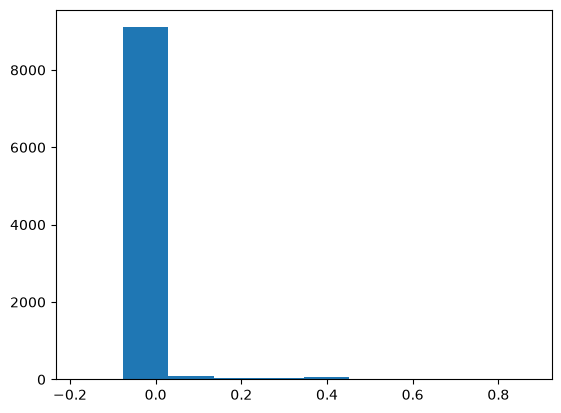

In [26]:
# olhando distribuição de df_20min
print("\nDescrição de dh_20min:")
display(
    d.describe(percentiles=percentis)
    .to_frame("dh_20min")
    .style.format("{:.5f}")
)

# fig, ax = plt.subplots(figsize=(10, 4))

# ax.hist(d, bins=100, density=True)

# ax.set_xlabel("Variação da umidade (p.p./min)")
# ax.set_ylabel("Densidade")
# ax.grid(alpha=0.2)

# plt.show()

# print(d.describe(
#     percentiles=[.05, .10, .25, .50, .75, .90, .95]
# ))

plt.hist(d)
plt.show()

maior parte das variações é pequena, com quedas mais frequentes que aumentos

In [27]:
# analise em cima dos 3 grupos para dh_20min
print("\nfrequencia de dh_20min:")
print("Quedas:", (d < 0).mean()*100)
print("Estáveis:", (d == 0).mean()*100)
print("Aumentos:", (d > 0).mean()*100)

# olhando distribuição das magnitudes de cada dh_20min não estavel (sem zeros)
quedas = -d[d < 0]
aumentos = d[d > 0]

q = [.25, .50, .75, .90, .95]

tabela = pd.DataFrame({
    "Percentil": ["P25", "P50", "P75", "P90", "P95"],
    "Quedas (magnitude)": quedas.quantile(q).values,
    "Aumentos": aumentos.quantile(q).values
})

display(
    tabela.style.format({
        "Quedas (magnitude)": "{:.5f}",
        "Aumentos": "{:.5f}"
    }).hide(axis="index")
)


frequencia de dh_20min:
Quedas: 43.82106844024887
Estáveis: 45.58034756490024
Aumentos: 10.598583994850891


Percentil,Quedas (magnitude),Aumentos
P25,0.00300,0.00250
P50,0.00500,0.00350
P75,0.01000,0.01463
P90,0.02130,0.24750
P95,0.03190,0.38865


* Até P75 -> as magnitudes das quedas e dos aumentos +- próximas.
* A partir de P90 -> aumentos com uma cauda muito mais forte

In [28]:
# # olhando concentrações ao redor de zero com os percentis p25,p50, p75 de queda e subida -> 
# #       para escolher um limite da função de pertinência estável

# limites = sorted(set(
#     [0]
#     + quedas.quantile([.25, .50, .75]).tolist()
#     + aumentos.quantile([.25, .50, .75]).tolist()
# ))

# total = len(d)

# tabela = pd.DataFrame({
#     "Limite absoluto": limites,
#     "Quantidade": [
#         (d.abs() <= limite).sum()
#         for limite in limites
#     ]
# })

# tabela["Percentual"] = tabela["Quantidade"] / total

# display(
#     tabela.style.format({
#         "Limite absoluto": "{:.4f}",
#         "Quantidade": "{:,.0f}",
#         "Percentual": "{:.1%}"
#     }).hide(axis="index")
# )

trapezoide em queda e aumento 
* queda: (-0.606, -0.606, -0.012, 0)
* aumento: (0, 0.013, 0.9915, 0.9915)
* triangulo em estável (-0.012, 0, 0.013)

In [29]:
# def plot_serie(df, coluna, ts="ts_generation"):
#     datas = pd.to_datetime(df[ts], unit="ms")

#     plt.figure(figsize=(12, 4))
#     plt.plot(datas, df[coluna])
#     # plt.xlabel("Data")
#     plt.ylabel(coluna)
#     plt.grid(True)
#     plt.show()

# plot_serie(df_dinamica, "humidity_soil")
# plot_serie(df_dinamica, "dh_20min")

# # vendo a quantidade de zeros 
# print("Zeros exatos:", (d == 0).sum())
# print("Próximos de zero:", (d.abs() <= 0.005).sum())

# from IPython.display import display

# total = len(d)

# tabela = pd.DataFrame({
#     "Condição": [
#         "Variação exatamente zero",
#         "Variação entre ±0,005",
#         "Variação acima de ±0,005"
#     ],
#     "Quantidade": [
#         (d == 0).sum(),
#         (d.abs() <= 0.005).sum(),
#         (d.abs() > 0.005).sum()
#     ]
# })

# tabela["Percentual"] = tabela["Quantidade"] / total

# display(
#     tabela.style.format({
#         "Quantidade": "{:,.0f}",
#         "Percentual": "{:.1%}"
#     }).hide(axis="index")
# )

## Aplicando Fuzzy

In [30]:
# # verificando universos
# df_aut['diferenca'] = df_aut["humidity_soil"] - df_aut["humidity_soil_lag_10"]
# df_aut['tend'] = (df_aut["humidity_soil"] - df_aut["humidity_soil_lag_20"]) / 20

# def buscandoPossivelStep(column):
#     values = np.unique(column)
#     diffs = np.diff(values)
#     step = np.median(diffs)
#     return step

# step_diff = buscandoPossivelStep(df_aut['diferenca'])
# step_tend = buscandoPossivelStep(df_aut['tend'])
# print(step_diff, step_tend, sep='\n')

In [31]:
import skfuzzy as fuzz
from skfuzzy import control as ctrl

/home/anderson/Documentos/pi4/PI4comIOT/projeto-integrador-iv-mitha/.venv/lib/python3.12/site-packages/skfuzzy/control/fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


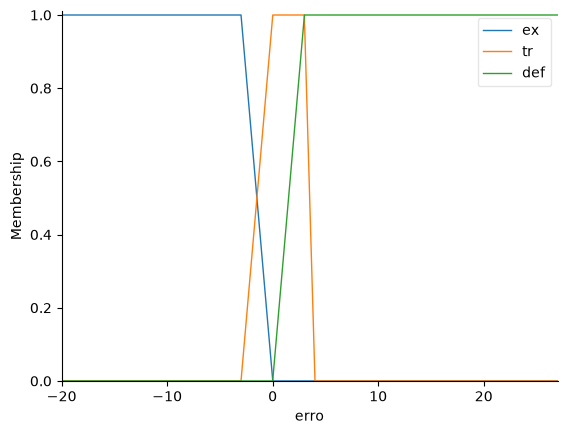

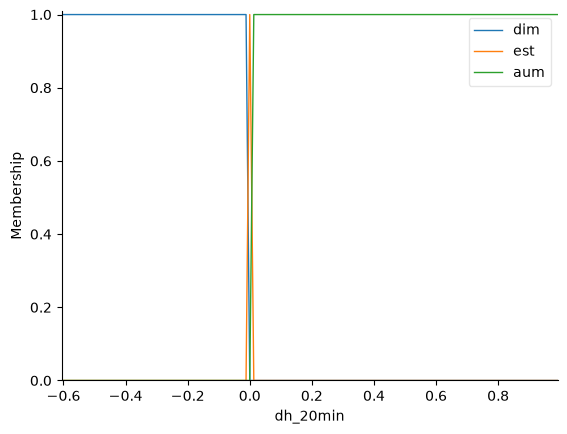

In [32]:
# Entrada erro
erro = ctrl.Antecedent(
    np.linspace(-20, 27, 4701),
    "erro"
)

erro["ex"] = fuzz.trapmf(
    erro.universe, [-20, -20, -3, 0]
)

erro["tr"] = fuzz.trapmf(
    erro.universe, [-3, 0, 3, 4]
)

erro["def"] = fuzz.trapmf(
    erro.universe, [0, 3, 27, 27]
)

# Entrada variação média da umidade
dh = ctrl.Antecedent(
    np.linspace(-0.606, 0.9915, 3196),
    "dh_20min"
)

dh["dim"] = fuzz.trapmf(
    dh.universe, [-0.606, -0.606, -0.012, 0]
)

dh["est"] = fuzz.trimf(
    dh.universe, [-0.012, 0, 0.013]
)

dh["aum"] = fuzz.trapmf(
    dh.universe, [0, 0.013, 0.9915, 0.9915]
)

erro.view()
dh.view()

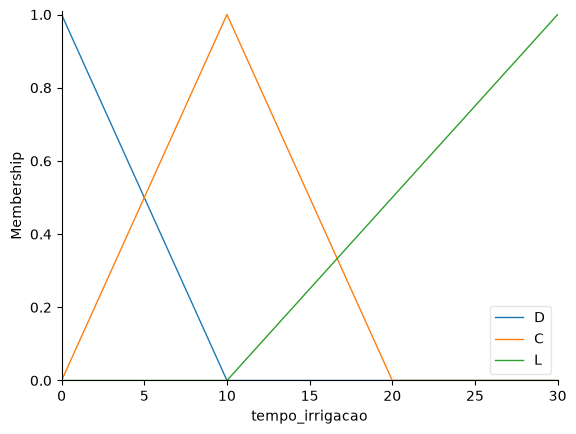

In [33]:
ti = ctrl.Consequent( # tem que avaliar depois com a bomba física
    np.linspace(0, 30, 301),
    "tempo_irrigacao"
)

# desligado
ti["D"] = fuzz.trimf(
    ti.universe, [0, 0, 10]
)

# ligado tempo curto
ti["C"] = fuzz.trimf(
    ti.universe, [0, 10, 20]
)

# ligado tempo longo
ti["L"] = fuzz.trimf(
    ti.universe, [10, 30, 30]
)

ti.view()

### regras

In [34]:
regra1 = ctrl.Rule(erro['ex'] & dh['dim'], ti['C'])
regra2 = ctrl.Rule(erro['ex'] & dh['est'], ti['D'])
regra3 = ctrl.Rule(erro['ex'] & dh['aum'], ti['D'])

regra4 = ctrl.Rule(erro['tr'] & dh['dim'], ti['C'])
regra5 = ctrl.Rule(erro['tr'] & dh['est'], ti['C'])
regra6 = ctrl.Rule(erro['tr'] & dh['aum'], ti['D'])

regra7 = ctrl.Rule(erro['def'] & dh['dim'], ti['L'])
regra8 = ctrl.Rule(erro['def'] & dh['est'], ti['L'])
regra9 = ctrl.Rule(erro['def'] & dh['aum'], ti['C'])

regras = [
    regra1, regra2, regra3,
    regra4, regra5, regra6, 
    regra7, regra8, regra9,
]

## SIMULANDO

## REMOÇÃO OUTLIERS

In [35]:
from src.utils.pca import pca, t2_q, remove_anomalias_t2_q
from sklearn.model_selection import train_test_split

seed = 42

def outlier_iqr(
    df: pd.DataFrame,
    columns: list | None = None,
    show: bool = True,
    remove: bool = False
):
    if columns is None:
        columns = df.columns

    df_iqr = df.copy()

    contagem_por_coluna = {}
    mask_remover = pd.Series(False, index=df_iqr.index)

    for column in columns:
        q1 = df_iqr[column].quantile(0.25)
        q3 = df_iqr[column].quantile(0.75)

        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        mask_outlier = (
            (df_iqr[column] < lower) |
            (df_iqr[column] > upper)
        )

        outlier_num = mask_outlier.sum()

        contagem_por_coluna[column] = outlier_num
        mask_remover |= mask_outlier

        if show:
            print(
                f"Quantidade de outliers da coluna "
                f"{column}: {outlier_num}"
            )

    idx_removidos = df_iqr.index[mask_remover]

    if remove:
        df_iqr = df_iqr.loc[~mask_remover].copy()

    return df_iqr, idx_removidos, contagem_por_coluna

def clean_anormaly(df, PARAMS, cols_meta, cols_target, flag_pca: bool = True, cutoff: str = None, save_flag: bool =  False, sufix_file = "none", name_dir = "none" ):
    cols_features = [c for c in df.columns if c not in cols_meta + cols_target]

    # treino e teste
    if cutoff is None:
        train_idx, test_idx = train_test_split(df.index, test_size=0.3, random_state=seed, shuffle=False)
    else:
        limite = pd.Timestamp(cutoff).value // 1_000_000
        train_idx = df.index[df["ts_generation"] < limite]
        test_idx = df.index[df["ts_generation"] >= limite]
    # sem split temporal por enquanto...

    train_df = df.loc[train_idx, cols_meta + cols_features + cols_target]
    df_test  = df.loc[test_idx,  cols_meta + cols_features + cols_target]

    # iqr
    train_df, idx_removidos_iqr, contagem_por_coluna = outlier_iqr(
        train_df.copy(),
        PARAMS,
        remove=True,
        show=False
    )

    ## REMOVENDO AUSENTES!!!
    train_df = train_df.dropna(subset=PARAMS + cols_target)

    print("\n================ IQR ================")
    print(f"Total de linhas removidas pelo IQR: {len(idx_removidos_iqr)}")

    print("\nColunas responsáveis pela remoção:")

    for col, qtd in contagem_por_coluna.items():
        if qtd > 0:
            print(f"{col}: {qtd} valores fora do IQR")

    if flag_pca:
        X_train = train_df[PARAMS]
        meta_train = train_df[cols_meta]
        cols_restantes = train_df.columns.difference(PARAMS + cols_meta).tolist()
        y_train = train_df[cols_restantes]

        # aplicando pca
        vals, vecs, scaler, Z_train = pca(X_train=X_train)

        # aplicando t2q
        res = t2_q(Z_train, vals, vecs, k=3, name_IMG=sufix_file)

        # removendo anomalias t2q
        X_train_clean, y_train_clean, meta_train_clean = remove_anomalias_t2_q(X_train, y_train, res, meta_train)
        train_df = pd.concat([meta_train_clean, X_train_clean, y_train_clean], axis=1)

    # if save_flag:
    #     save_file(train_df, name=f"train_{sufix_file}", name_dir=name_dir)
    #     save_file(df_test, name=f"test_{sufix_file}", name_dir=name_dir)

    return train_df, df_test



================ IQR ================
Total de linhas removidas pelo IQR: 4

Colunas responsáveis pela remoção:
humidity_soil: 1 valores fora do IQR
temperature_env: 2 valores fora do IQR
humidity_env: 1 valores fora do IQR
Total de linhas removidas por T² + Q: 0


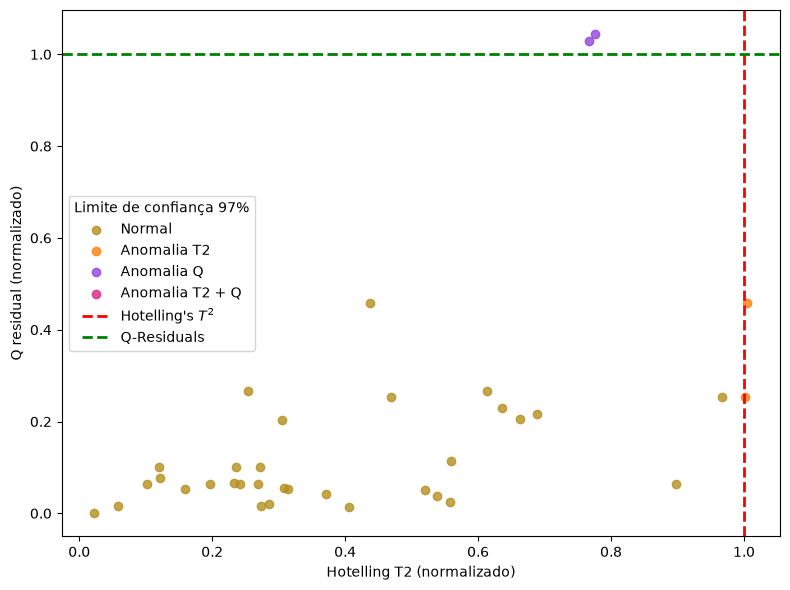

In [36]:
PARAMS = [
    'humidity_soil',
    'temperature_env',
    'humidity_env',
]

cols_meta = ['ts_generation']
cols_target = ['t_pi']

df_eventos = tempo_proximo_evento(registros_valve)[["ts_generation", "t_pi"]].merge(
    df_aut[["ts_generation", *PARAMS]], on="ts_generation", how="inner",
).dropna(subset=cols_target)
train_df, test_df = clean_anormaly(df_eventos, PARAMS=PARAMS, cols_meta=cols_meta, cols_target=cols_target)

2024-06-12 12:28:05.784000


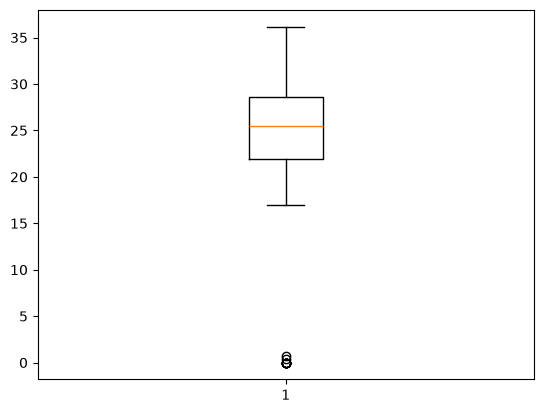

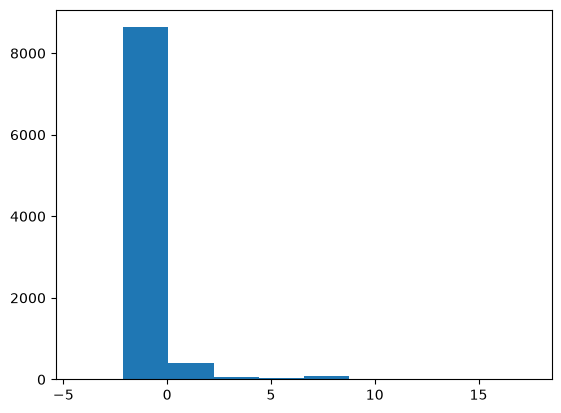

In [37]:
import matplotlib.pyplot as plt
df_aut_t = df_aut.copy()

# # quando humidity_soil != 0:
df_aut_t["date"] = pd.to_datetime(df_aut_t["ts_generation"], unit="ms")
mask = df_aut_t["humidity_soil"].ne(0.0)
date = df_aut_t.loc[mask, "date"].iloc[0]

print(date)
df_aut_t = df_aut_t[df_aut_t["date"] > date]

# # plt.plot(df_aut_t["humidity_soil"])
plt.boxplot(df_aut_t["humidity_soil"])
plt.show()

# tendencia
df_aut_t["tend"] = df_aut_t["humidity_soil"] - df_aut_t["humidity_soil_lag_3"]
# df_aut_t.head(5)

plt.hist(df_aut_t["tend"])
# plt.xlim(-5,5)
plt.show()

MODEL